# PyTorch: Autoencoder convolucional Fashion-MNIST

## Refs.

* https://pytorch.org/tutorials/beginner/basics/optimization_tutorial.html
* https://github.com/zalandoresearch/fashion-mnist
* https://pytorch.org/docs/stable/generated/torch.nn.Conv2d.html
* https://pytorch.org/docs/stable/generated/torch.nn.ConvTranspose2d.html
* V. Dumoulin y F. Visin, *A guide to convolution arithmetic for deep learning*, https://arxiv.org/abs/1603.07285

## **Ejercicio 1)** Preparando el entorno

**1)** De ser necesario, instale **PyTorch** y **torchvision** (en Google Colab ya vienen instalados):

    !pip3 install torch torchvision

**2)** Importe `matplotlib.pyplot`, `numpy`, `torch`, `torch.nn`, las clases `Dataset` y `DataLoader` de `torch.utils.data`, y los módulos `datasets` y `transforms` de `torchvision`.

**3)** Determine en qué dispositivo (`device`) va a trabajar: una **CPU** o una **GPU**.
Fije las semillas de los generadores de números aleatorios para que los resultados sean reproducibles.

In [ ]:
# 1.1)
#!pip3 install torch torchvision

In [ ]:
# 1.2)
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms

In [ ]:
# 1.3)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.manual_seed(0)
np.random.seed(0)
print("device =", device)

device = cpu


## **Ejercicio 2)** Bajando y jugando con el dataset **Fashion-MNIST**

**1)** Baje y transforme los conjuntos de entrenamiento y validación de Fashion-MNIST, de modo que cada imagen sea un tensor de dimensiones $(1,28,28)$ con valores en el intervalo $[0,1]$.

**IMPORTANTE:** Más adelante, la salida del autoencoder pasará por una `Sigmoid`, que toma valores en $(0,1)$.
Por lo tanto, **no** normalice las imágenes al intervalo $[-1,1]$ (p.ej. con `transforms.Normalize((0.5,),(0.5,))`): de hacerlo, el autoencoder no podría reconstruir los píxeles negativos.

**2)** Grafique un mosaico de $3\times 3$ imágenes de Fashion-MNIST, cada una titulada con el nombre de su respectiva clase.

In [ ]:
# 2.1)
# ToTensor() convierte la imagen PIL a un tensor (1,28,28) con valores en [0,1]
transform = transforms.ToTensor()
train_set_orig = datasets.FashionMNIST('MNIST_data/', download=True, train=True,  transform=transform)
valid_set_orig = datasets.FashionMNIST('MNIST_data/', download=True, train=False, transform=transform)
print(len(train_set_orig), len(valid_set_orig))
image, label = train_set_orig[0]
print(image.shape, image.min().item(), image.max().item())

100%|██████████| 26.4M/26.4M [00:01<00:00, 18.8MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 304kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 5.57MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 18.2MB/s]

60000 10000
torch.Size([1, 28, 28]) 0.0 1.0


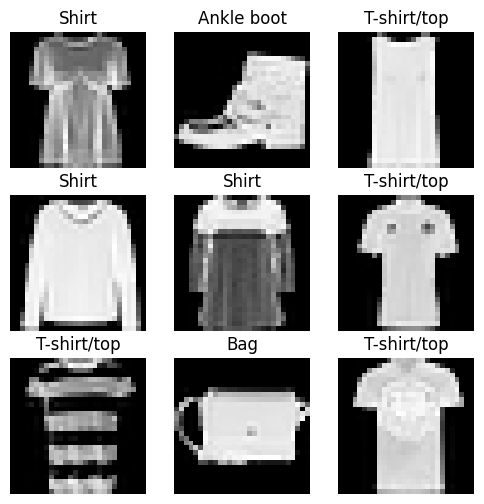

In [ ]:
# 2.2)
labels_names = train_set_orig.classes # ['T-shirt/top', 'Trouser', ..., 'Ankle boot']
figure = plt.figure(figsize=(6,6))
rows, cols = 3, 3
for i in range(1, rows*cols+1):
    j = torch.randint(len(train_set_orig), size=(1,)).item()
    image, label = train_set_orig[j]
    figure.add_subplot(rows, cols, i)
    plt.title(labels_names[label])
    plt.axis("off")
    plt.imshow(image.squeeze(), cmap="Greys_r")
plt.show()

## **Ejercicio 3)** Creando un `Dataset` personalizado

**1)** Con el fin de entrenar un autoencoder, defina una clase `CustomDataset` derivada de la clase `Dataset`, cuyo método `__getitem__(self,i)` retorne el par `(input,output)`, donde tanto `input` como `output` son iguales a la $i$-ésima imagen del dataset original (en vez del par `(imagen,label)`).

**2)** Utilice dicha clase para transformar los conjuntos de entrenamiento y validación de Fashion-MNIST, pensados para clasificación, en conjuntos pensados para entrenar un autoencoder.

In [ ]:
# 3.1)
class CustomDataset(Dataset):
    def __init__(self, dataset):
        self.dataset = dataset
    def __len__(self):
        return len(self.dataset)
    def __getitem__(self, i):
        image, label = self.dataset[i]
        return image, image # input = output = imagen

In [ ]:
# 3.2)
train_set = CustomDataset(train_set_orig)
valid_set = CustomDataset(valid_set_orig)

## **Ejercicio 4)** Red neuronal autoencoder convolucional

Para una entrada de tamaño $H_{in}$ (por dimensión espacial), las capas `Conv2d` (y `MaxPool2d`) y `ConvTranspose2d` producen salidas de tamaño
$$
H_{out}^{\rm conv} = \left\lfloor \frac{H_{in} + 2\,{\rm padding} - {\rm kernel}}{\rm stride} \right\rfloor + 1,
\qquad
H_{out}^{\rm convT} = (H_{in}-1)\,{\rm stride} - 2\,{\rm padding} + {\rm kernel} + {\rm output\_padding},
$$
respectivamente (con `dilation=1`).
La convolución transpuesta **no** es la inversa de la convolución: es la transpuesta (adjunta) de la transformación lineal que define una convolución con los mismos parámetros.
Por eso mapea tamaños "chicos" en tamaños "grandes", invirtiendo las *dimensiones* (no los valores), lo que la hace útil como capa de "des-convolución" o *upsampling* aprendible.

**1)** Usando las fórmulas de arriba, verifique que una `Conv2d` con kernel $3$ mapea $28\to 26$, que una `MaxPool2d` con kernel $2$ mapea $26\to 13$, y que una `ConvTranspose2d` con kernel $6$, stride $2$ y padding $1$ mapea $13\to 28$.

**2)** Defina una red neuronal *autoencoder convolucional* constituida por los siguientes bloques:

1. **Encoder** convolucional:
   * Una capa `Conv2d` que mapea una entrada con $1$ canal y dimensiones $(28,28)$ a una salida con $16$ canales y dimensiones $(26,26)$. Utilice un kernel de dimensiones $(3,3)$ y el resto de los parámetros en sus valores por defecto.
   * Una capa `ReLU`.
   * Una capa `MaxPool2d` con un kernel de dimensiones $(2,2)$, de modo que la salida resultante tenga dimensiones $(16,13,13)$.
   * Una capa `Dropout` con probabilidad $p$.

2. **Cuello de botella** (*bottleneck*) lineal:
   * Una capa `Flatten` que transforma una entrada de dimensiones $(16,13,13)$ en un vector de dimensión $16\times 13\times 13 = 2704$.
   * Una capa `Linear` que mapea el vector de dimensión $2704$ a un vector de dimensión $n$ (con $n\ll 784$, por ejemplo $n=128$), que representa la *codificación latente* comprimida.
   * Una capa `ReLU`.
   * Una capa `Linear` que mapea de nuevo el vector de dimensión $n$ a un vector de dimensión $2704$.
   * Una capa `ReLU`.

3. **Decoder** convolucional transpuesto:
   * Una capa `Unflatten` que mapea el vector de dimensión $2704$ a un tensor de $16$ canales con dimensiones $(13,13)$.
   * Una capa `ConvTranspose2d` que mapea $16$ canales de dimensiones $(13,13)$ a $1$ canal de dimensiones $(28,28)$. Utilice un kernel de dimensiones $(6,6)$, un stride de $(2,2)$ y un padding de $(1,1)$.
   * Una capa `Sigmoid`, para asegurar que las salidas se encuentren en el rango $[0,1]$, al igual que las imágenes de entrada.

Verifique, con un tensor de entrada aleatorio de dimensiones $(1,1,28,28)$, que la salida tiene las mismas dimensiones que la entrada.

**3)** Grafique, a modo de comparación, algunas imágenes de entrada y sus correspondientes reconstrucciones obtenidas con el modelo **sin entrenar**, con una probabilidad de *dropout* $p=0.2$.

In [ ]:
# 4.1)

In [ ]:
# 4.2)

In [ ]:
# 4.3)

## **Ejercicio 5)** Entrenando el modelo

**1)** Implemente, en una función, un loop de entrenamiento que recorra los lotes (*batches*) y retorne la pérdida promedio sobre la época.

**2)** Implemente, en una función, un loop de validación que recorra los lotes y retorne la pérdida promedio.

**3)** Cree dos `DataLoader`s, `train_loader` y `valid_loader`, definidos sobre `train_set` y `valid_set`, respectivamente, que usen lotes de 100 ejemplos.

**4)** Cree una función de pérdida usando el **error cuadrático medio** (ECM).

**5)** Cree una instancia del modelo con dropout $p=0.2$ y cópiela al dispositivo de trabajo.

**6)** Cree un optimizador **ADAM** con un learning rate igual a $10^{-3}$.

**7)** Implemente un loop que itere sobre épocas de entrenamiento y validación, y que guarde en listas los siguientes valores del ECM:
*  promedio (*incorrecto*) sobre el conjunto de entrenamiento, calculado **durante** el proceso de entrenamiento sobre la época;
*  promedio (correcto) sobre el conjunto de entrenamiento, calculado **posteriormente** al entrenamiento sobre la época;
*  promedio (correcto) sobre el conjunto de validación, calculado **posteriormente** al entrenamiento sobre la época.

¿Por qué el primero de estos promedios es "incorrecto"?

**IMPORTANTE:** No olvide copiar los lotes al dispositivo de trabajo.

**8)** Entrene y valide el modelo.

**9)** Use las listas del inciso **7)** para graficar, en función de las **épocas**, el ECM de **entrenamiento** y de **validación**.
Discuta y comente: ¿cuál es el número óptimo de épocas de entrenamiento?

**10)** Grafique, comparativamente, algunas imágenes del conjunto de validación y sus reconstrucciones obtenidas con el modelo entrenado.

**11)** Repita para otras elecciones de los hiperparámetros, tales como el optimizador (p.ej. **SGD**), el **learning rate**, el tamaño de los **lotes**, el **dropout**, la dimensión $n$ del **código latente**, y **capas convolucionales** y **convolucionales transpuestas** de otros tamaños.
En particular, pruebe eliminando, adecuadamente, el **cuello de botella lineal**.
¿Qué valores de estos hiperparámetros considera los más convenientes? ¿Por qué?

In [ ]:
# 5.1)

In [ ]:
# 5.2)

In [ ]:
# 5.3)

In [ ]:
# 5.4)

In [ ]:
# 5.5)

In [ ]:
# 5.6)

In [ ]:
# 5.7)

**Respuesta 5.7)**

In [ ]:
# 5.8)

In [ ]:
# 5.9)

**Respuesta 5.9)**

In [ ]:
# 5.10)

### 5.11) Exploración de hiperparámetros

Para que la exploración sea rápida, usamos menos épocas y no evaluamos sobre el conjunto de entrenamiento después de cada época.
Además de `Autoencoder`, definimos dos arquitecturas alternativas:

* `AutoencoderSinLineal`: elimina el cuello de botella lineal, conectando directamente la salida del encoder $(16,13,13)$ con la `ConvTranspose2d`.
  Notar que, sin cuello de botella, el "código" tiene dimensión $2704 > 784$: la red no está obligada a comprimir la información.
* `AutoencoderProfundo`: usa dos capas convolucionales con stride $2$ (en vez de `MaxPool2d`), $(1,28,28)\to(16,14,14)\to(32,7,7)$, un cuello de botella lineal de dimensión $n$, y dos capas convolucionales transpuestas que invierten las dimensiones, $(32,7,7)\to(16,14,14)\to(1,28,28)$.
  Aquí se necesita `output_padding=1`: con stride 2, tanto $14$ como $13$ se mapean a $7$, y `output_padding` desambigua el tamaño de salida de la convolución transpuesta.

In [ ]:
# 5.11)

**Respuesta 5.11)**